# Transfer Learning

The goal is create a neural network model to classify images of cats and dogs, using transfer learning. Therefore, I will use part of a pre-trained image classifier model (trained on ImageNet) as a feature extractor, and train additional new layers to perform the cats and dog classification task.

In [18]:
# Package and libraries import

import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
import numpy as np
import os
import pandas as pd
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns

##
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Input, Flatten, Dropout
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.callbacks import EarlyStopping


![Image](data/Cats-Dogs-Rex.jpg)

# The Dogs vs Cats Dataset
the [Dogs vs Cats dataset](https://www.kaggle.com/c/dogs-vs-cats/data) consist of 25000 images containing either a cat or a dog. To this project, I will use a subset of 600 images and labels. The dataset is a subset of a much larger dataset of 3 millions phtos that were originally used as a CAPTCHA.


* J. Elson, J. Douceur, J. Howell, and J. Saul. "Asirra: A CAPTCHA that Exploits Interest-Aligned Manual Image Categorization." Proceedings of 14th ACM Conference on Computer and Communications Security (CCS), October 2007.

Therefore the goal is to train a classifier model using of a pre-trained image classifier, using the principle of transfer learning.

### Load and preprocess the data


In [2]:
images_train = np.load('data/images_train.npy') / 255.0
images_valid = np.load('data/images_valid.npy') / 255.0
images_test = np.load('data/images_test.npy') / 255.0


labels_train = np.load('data/labels_train.npy')
labels_valid = np.load('data/labels_valid.npy')
labels_test = np.load('data/labels_test.npy')

In [3]:

print(f"{images_train.shape[0]} Training data examples")
print(f"{images_valid.shape[0]} Validation data examples")
print(f"{images_test.shape[0]} Test data examples")

600 Training data examples
300 Validation data examples
300 Test data examples


In [4]:
images_train[:2,:,:,:]

array([[[[0.10588235, 0.05098039, 0.        ],
         [0.11372549, 0.05882353, 0.00784314],
         [0.09019608, 0.03529412, 0.        ],
         ...,
         [0.17254902, 0.10588235, 0.00392157],
         [0.19215686, 0.1254902 , 0.02352941],
         [0.20392157, 0.1372549 , 0.03529412]],

        [[0.10196078, 0.04705882, 0.        ],
         [0.11764706, 0.0627451 , 0.01176471],
         [0.10196078, 0.04705882, 0.00392157],
         ...,
         [0.2       , 0.13333333, 0.03137255],
         [0.21568627, 0.14901961, 0.04705882],
         [0.22352941, 0.15686275, 0.05490196]],

        [[0.08627451, 0.03137255, 0.        ],
         [0.10196078, 0.04705882, 0.        ],
         [0.09411765, 0.03921569, 0.        ],
         ...,
         [0.19215686, 0.1254902 , 0.02352941],
         [0.20392157, 0.1372549 , 0.03529412],
         [0.21176471, 0.14509804, 0.04313725]],

        ...,

        [[0.30196078, 0.21568627, 0.07058824],
         [0.30980392, 0.22352941, 0.07843137]

### Display sample images and labels from the training dataset

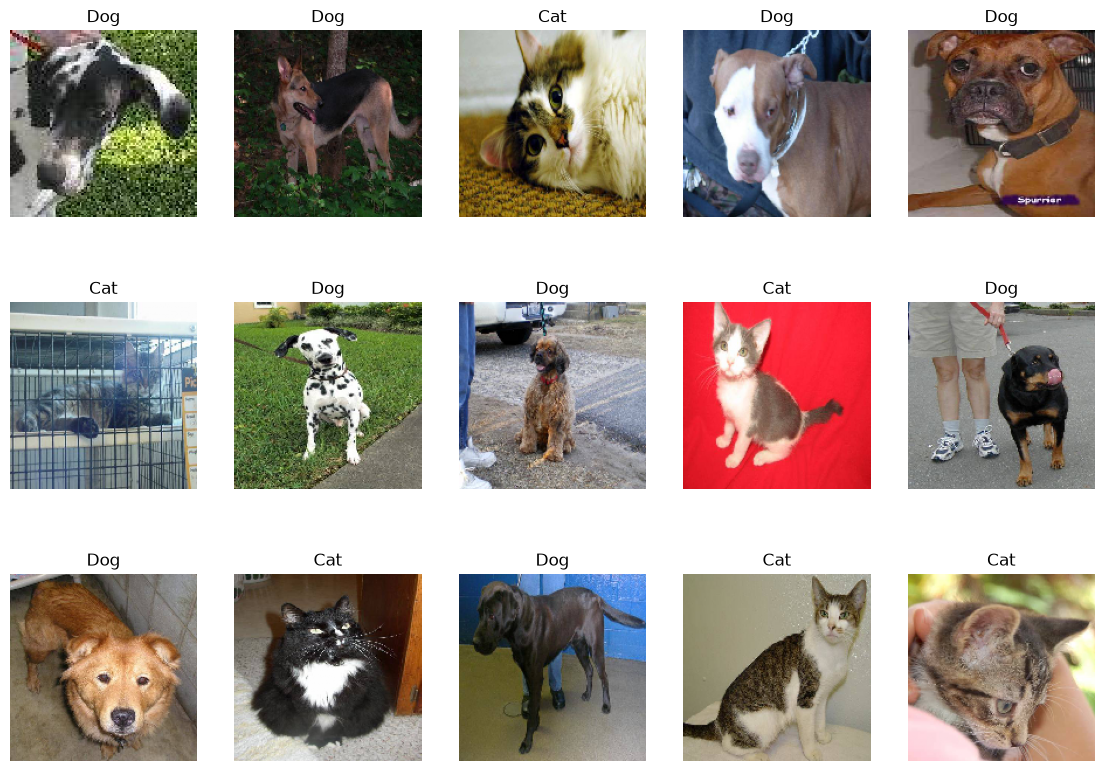

In [5]:

class_names = np.array(['Dog','Cat'])

plt.figure(figsize=(14,10))
idx = np.random.choice(images_train.shape[0], 15, replace=False)
for n, i in enumerate(idx):
    ax = plt.subplot(3,5,n+1)
    plt.imshow(images_train[i])
    plt.title(class_names[labels_train[i]])
    plt.axis('off')


## Creating a Benchmark Model

The benchmark model will be a CNN classifier model.

In [6]:

def get_benchmark_model(input_shape):

    inputs = Input(shape=input_shape)

    conv2d_1= Conv2D(32, (3,3), activation='relu', padding='same')(inputs)
    conv2d_2= Conv2D(32, (3,3), activation='relu', padding='same')(conv2d_1)

    maxpool_1 = MaxPooling2D(pool_size=(2,2))(conv2d_2)

    conv2d_3= Conv2D(64, (3,3), activation='relu', padding='same')(maxpool_1)
    conv2d_4= Conv2D(64, (3,3), activation='relu', padding='same')(conv2d_3)

    maxpool_2 = MaxPooling2D(pool_size=(2,2))(conv2d_4)

    conv2d_5= Conv2D(128, (3,3), activation='relu', padding='same')(maxpool_2)
    conv2d_6= Conv2D(128, (3,3), activation='relu', padding='same')(conv2d_5)

    maxpool_3 = MaxPooling2D(pool_size=(2,2))(conv2d_6)

    flatten = Flatten()(maxpool_3)

    dense_1 = Dense(128, activation='relu')(flatten)

    outputs = Dense(1, activation='sigmoid')(dense_1)

    model = Model(inputs=inputs, outputs=outputs)

    optimizer = RMSprop(learning_rate=0.001)

    model.compile(optimizer=optimizer, loss='binary_crossentropy',
                  metrics=['binary_accuracy'])

    return model





In [7]:

benchmark_model = get_benchmark_model(images_train[0].shape)
benchmark_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 160, 160, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 80, 80, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     6,553,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,840,865 (26.10 MB)

 Trainable params: 6,840,865 (26.10 MB)

 Non-trainable params: 0 (0.00 B)

## Train the CNN Benchmark Model

In [8]:
earlystopping = EarlyStopping(patience=2)

history_benchmark = benchmark_model.fit(images_train, labels_train, epochs=10,
                                        batch_size=32,
                                        validation_data=(images_valid, labels_valid),
                                        callbacks=[earlystopping])

Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 6s 254ms/step - binary_accuracy: 0.5150 - loss: 0.9446 - val_binary_accuracy: 0.5000 - val_loss: 0.6927
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 238ms/step - binary_accuracy: 0.4933 - loss: 0.6935 - val_binary_accuracy: 0.5000 - val_loss: 0.6915
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 238ms/step - binary_accuracy: 0.5233 - loss: 0.7218 - val_binary_accuracy: 0.5233 - val_loss: 0.6926
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 256ms/step - binary_accuracy: 0.5250 - loss: 0.6951 - val_binary_accuracy: 0.5000 - val_loss: 0.6902
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 239ms/step - binary_accuracy: 0.5467 - loss: 0.7391 - val_binary_accuracy: 0.5167 - val_loss: 0.6912
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 231ms/step - binary_accuracy: 0.5450 - loss: 0.6893 - val_binary_accuracy: 0.5933 - val_loss: 0.6838
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 4s 223ms/step - binary_accuracy: 0.5733 - loss: 0.6910 - val_binary_accuracy: 0.5567 - val_loss: 0.6890
Epoch 

## Plotting the Learning curves

In [9]:
print(history_benchmark.history.keys())

dict_keys(['binary_accuracy', 'loss', 'val_binary_accuracy', 'val_loss'])


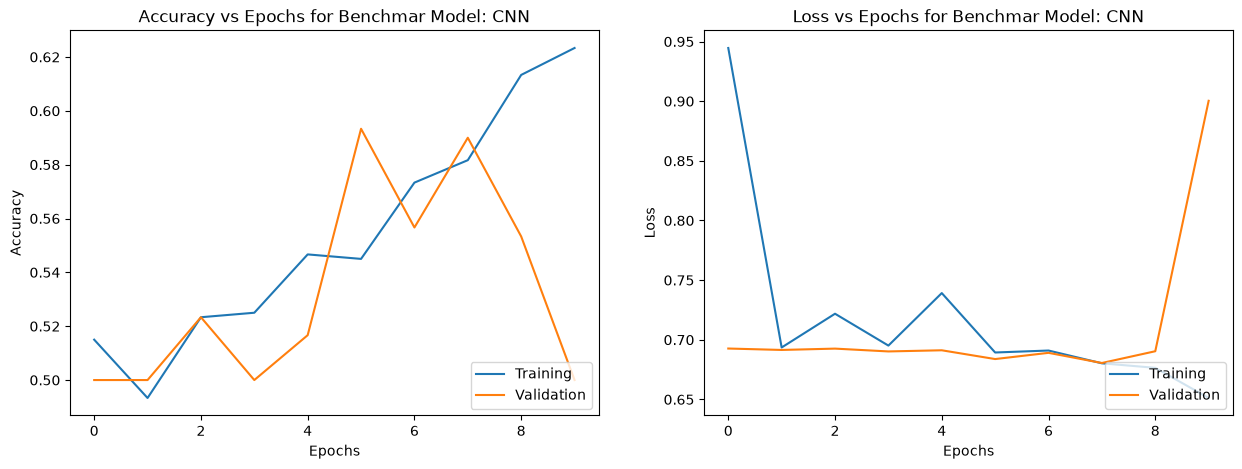

In [10]:
plt.figure(figsize=(15,5))
plt.subplot(121)
try: 
    plt.plot(history_benchmark.history['binary_accuracy'])
    plt.plot(history_benchmark.history['val_binary_accuracy'])
except KeyError:
    plt.plot(history_benchmark.history['acc'])
    plt.plot(history_benchmark.history['val_acc'])

plt.title('Accuracy vs Epochs for Benchmar Model: CNN')
plt.ylabel('Accuracy')
plt.xlabel('Epochs')
plt.legend(['Training', 'Validation'], loc= 'lower right')

plt.subplot(122)
plt.plot(history_benchmark.history['loss'])
plt.plot(history_benchmark.history['val_loss'])
plt.title('Loss vs Epochs for Benchmar Model: CNN')
plt.ylabel('Loss')
plt.xlabel('Epochs')
plt.legend(['Training', 'Validation'], loc= 'lower right')


The benchmark model have a complex structure with many parameters. Therefore, train this model we only 600 images produce that the model don't learning well. To improve the performance of the model we have to increase the size of the dataset.


## Evaluate the benchmark model

In [11]:

benchmark_test_loss, benchmark_test_acc = benchmark_model.evaluate(
    images_test, labels_test, verbose=2)

print(f"Test Loss: {benchmark_test_loss}")
print(f"Test Accuracy: {benchmark_test_acc}")


10/10 - 1s - 52ms/step - binary_accuracy: 0.5200 - loss: 0.8835
Test Loss: 0.8835046291351318
Test Accuracy: 0.5199999809265137


## Load the pretrained image classifier model

The idea is build other image classifier using transfer learning. So for this I will use the pre-trained MobileNet V2 model [Keras Applications](https://keras.io/applications/#mobilenetv2). For this case I have already downloaded the pretrained model

In [14]:

def load_pretrained_MobileNetV2(path):

    model_mobilenet = tf.keras.models.load_model(path)

    return model_mobilenet



In [15]:

base_model = load_pretrained_MobileNetV2('models/MobileNetV2.h5')
base_model.summary()

Model: "mobilenetv2_1.00_160"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_6             │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_pad           │ (None, 161, 161,  │          0 │ input_6[0][0]     │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 80, 80,    │        864 │ Conv1_pad[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 80, 80,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 80, 80,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 80, 80,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 80, 80,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 80, 80,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 80, 80,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 80, 80,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 81, 81,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 40, 40,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 40, 40,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 40, 40,    │          0 │ block_1_depthwis

 Total params: 3,538,984 (13.50 MB)

 Trainable params: 3,504,872 (13.37 MB)

 Non-trainable params: 34,112 (133.25 KB)

## Using the pre-trained model as a feature extractor

The idea is remove the final layer of the network and replace it with new, untrained classifier layers of our task. 

In [16]:

def remove_head(pretrained_model):

    inputs = pretrained_model.input
    outputs = pretrained_model.get_layer('global_average_pooling2d_6').output
    model = Model(inputs=inputs, outputs=outputs)

    return model


In [17]:

feature_extractor = remove_head(base_model)
feature_extractor.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_6             │ (None, 160, 160,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_pad           │ (None, 161, 161,  │          0 │ input_6[0][0]     │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 80, 80,    │        864 │ Conv1_pad[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 80, 80,    │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 80, 80,    │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 80, 80,    │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 80, 80,    │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 80, 80,    │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 80, 80,    │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 80, 80,    │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 80, 80,    │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 81, 81,    │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 40, 40,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 40, 40,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 40, 40,    │          0 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 2,223,872 (8.48 MB)

 Non-trainable params: 34,112 (133.25 KB)

Now I can construct new final classifier layers. For this I will use the Sequential API.

In [25]:

def add_new_classifier_head(feature_extractor):
    model = Sequential([
        feature_extractor,
        Dense(32, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])

    return model


In [26]:

new_model = add_new_classifier_head(feature_extractor)
new_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional_1 (Functional)       │ (None, 1280)           │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │        40,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,299,009 (8.77 MB)

 Trainable params: 2,264,897 (8.64 MB)

 Non-trainable params: 34,112 (133.25 KB)

## Freeze the weights of the pretrained model

Now I will freeze the weights of the pre-trained feature extractor, so that only weights of the new layers will change during the training

In [27]:


def freeze_pretrained_layers(model):
    model.layers[0].trainable = False

    optimizer = RMSprop(learning_rate=0.001)

    model.compile(optimizer=optimizer, loss='binary_crossentropy',
                  metrics=['binary_accuracy'])

    return model

In [28]:

frozen_new_model = freeze_pretrained_layers(new_model)
frozen_new_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ functional_1 (Functional)       │ (None, 1280)           │     2,257,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │        40,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,299,009 (8.77 MB)

 Trainable params: 41,025 (160.25 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

# Training the model

In [29]:
earlystopping = EarlyStopping(patience=2)

history_frozen_new_model = frozen_new_model.fit(
    images_train, labels_train, epochs=10, batch_size=32,
    validation_data=(images_valid, labels_valid),
    callbacks=[earlystopping]
)

Epoch 1/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 5s 148ms/step - binary_accuracy: 0.8983 - loss: 0.2821 - val_binary_accuracy: 0.9433 - val_loss: 0.1420
Epoch 2/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - binary_accuracy: 0.9517 - loss: 0.1293 - val_binary_accuracy: 0.9467 - val_loss: 0.1271
Epoch 3/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - binary_accuracy: 0.9600 - loss: 0.1090 - val_binary_accuracy: 0.9400 - val_loss: 0.1123
Epoch 4/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - binary_accuracy: 0.9700 - loss: 0.0745 - val_binary_accuracy: 0.9433 - val_loss: 0.1370
Epoch 5/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - binary_accuracy: 0.9800 - loss: 0.0596 - val_binary_accuracy: 0.9467 - val_loss: 0.1069
Epoch 6/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - binary_accuracy: 0.9850 - loss: 0.0380 - val_binary_accuracy: 0.9500 - val_loss: 0.1145
Epoch 7/10
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step - binary_accuracy: 0.9850 - loss: 0.0441 - val_binary_accuracy: 0.9433 - val_loss: 0.1238


## Plot the learning curves